# Modelling Human Activity States with a Hidden Markov Model

In this notebook I use my own phone recordings of four activities (standing, walking, jumping, and the phone lying still on a table) to build a Hidden Markov Model that works out which activity I was doing from the sensor data alone.

The steps are:

1. Load the labelled accelerometer and gyroscope recordings.
2. Resample everything to one sampling rate.
3. Split the signals into windows and compute time and frequency features.
4. Build a Gaussian HMM from scratch in numpy (forward-backward, Baum-Welch and Viterbi).
5. Test it on recordings the model never saw during training.

All figures are saved to `report/figures/` so I can use them in the report.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

DATA_DIR = Path(os.environ.get("HMM_DATA_DIR", "data"))
FIG_DIR = Path(os.environ.get("HMM_FIG_DIR", "report/figures"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]
COLORS = {"standing": "#4C72B0", "walking": "#55A868", "jumping": "#C44E52", "still": "#8172B2"}
SIGNALS = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]

TARGET_FS = 50        # Hz: common rate every recording is resampled to
WINDOW_S = 2.0        # window length (s)
HOP_S = 1.0           # step between windows (s) -> 50 % overlap
TRIM_S = 0.5          # seconds cut from each end of a recording (tap-to-start/stop artefacts)
SESSION_GAP_S = 300   # training clips recorded < 5 min apart are chained into one sequence
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data collection and quality check

I recorded the data with Sensor Logger and used `prepare_data.py` to turn each export into one CSV file with the columns `timestamp, acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z, activity`. Accelerometer values are in m/s² and include gravity; gyroscope values are in rad/s. The training clips (5 to 10 s each, one activity per clip) are in `data/train/`. The recordings in `data/test/` are only used at the end, for evaluation.

The cells below check that every activity has at least 90 s of training data, flag clips outside the 5 to 10 s range, and look for gaps in the timestamps.

In [2]:
def load_split(split):
    recs = []
    for path in sorted((DATA_DIR / split).glob("*.csv")):
        df = pd.read_csv(path)
        t = df["timestamp"].to_numpy(float)
        dt = np.diff(t)
        recs.append(dict(
            file=path.name, split=split, df=df, start=t[0],
            duration_s=t[-1] - t[0], n_samples=len(df),
            native_fs=(len(t) - 1) / (t[-1] - t[0]),
            jitter_pct=100 * dt.std() / dt.mean(), max_gap_s=dt.max(),
            activity=df["activity"].iloc[0] if df["activity"].nunique() == 1 else "mixed",
        ))
    return recs

train_recs, test_recs = load_split("train"), load_split("test")
assert train_recs, f"No CSV files in {DATA_DIR / 'train'} - run `python prepare_data.py` first."

info = pd.DataFrame([{k: v for k, v in r.items() if k != "df"} for r in train_recs + test_recs])
print(f"{len(train_recs)} training files, {len(test_recs)} test files\n")
info.drop(columns="start").round(2)

61 training files, 3 test files



,file,split,duration_s,n_samples,native_fs,jitter_pct,max_gap_s,activity
0,alliane_jumping_01.csv,train,8.90,888,99.68,3.20,0.02,jumping
1,alliane_jumping_02.csv,train,7.96,795,99.81,0.00,0.01,jumping
2,alliane_jumping_03.csv,train,9.26,924,99.70,3.09,0.02,jumping
3,alliane_jumping_04.csv,train,6.19,619,99.82,0.01,0.01,jumping
4,alliane_jumping_05.csv,train,6.23,623,99.82,0.01,0.01,jumping
...,...,...,...,...,...,...,...,...
59,alliane_walking_15.csv,train,7.91,790,99.80,0.44,0.01,walking
60,alliane_walking_16.csv,train,6.66,665,99.67,3.64,0.02,walking
61,alliane_mixed_01.csv,test,46.02,4593,99.79,1.39,0.02,mixed
62,alliane_mixed_02.csv,test,43.72,4364,99.78,1.43,0.02,mixed


In [3]:
# Seconds of data per activity (a mixed test file contributes to several activities)
def seconds_per_activity(recs):
    out = {a: 0.0 for a in ACTIVITIES}
    for r in recs:
        counts = r["df"]["activity"].value_counts()
        for a, n in counts.items():
            if a in out:                     # skip "transition" seconds in test files
                out[a] += n / r["native_fs"]
    return out

coverage = pd.DataFrame({
    "train files": [sum(r["activity"] == a for r in train_recs) for a in ACTIVITIES],
    "train seconds": list(seconds_per_activity(train_recs).values()),
    "test seconds": list(seconds_per_activity(test_recs).values()),
}, index=ACTIVITIES).round(1)
coverage.loc["total"] = coverage.sum()
coverage["meets 90 s"] = coverage["train seconds"] >= 90
display(coverage)

short = info[(info.split == "train") & ((info.duration_s < 5) | (info.duration_s > 10.5))]
gaps = info[info.max_gap_s > 0.1]
print("Clips outside 5-10 s:", "none" if short.empty else ", ".join(short.file))
print("Files with a timestamp gap > 0.1 s:", "none" if gaps.empty else ", ".join(gaps.file))

,train files,train seconds,test seconds,meets 90 s
standing,15.0,103.7,29.0,True
walking,16.0,118.9,33.0,True
jumping,15.0,98.1,31.0,True
still,15.0,99.5,30.0,True
total,61.0,420.2,123.0,True


Clips outside 5-10 s: none
Files with a timestamp gap > 0.1 s: none


Native sampling rate: median 99.8 Hz, min 99.6 Hz, max 99.8 Hz
Timestamp jitter: median 0.0 % of the sampling interval


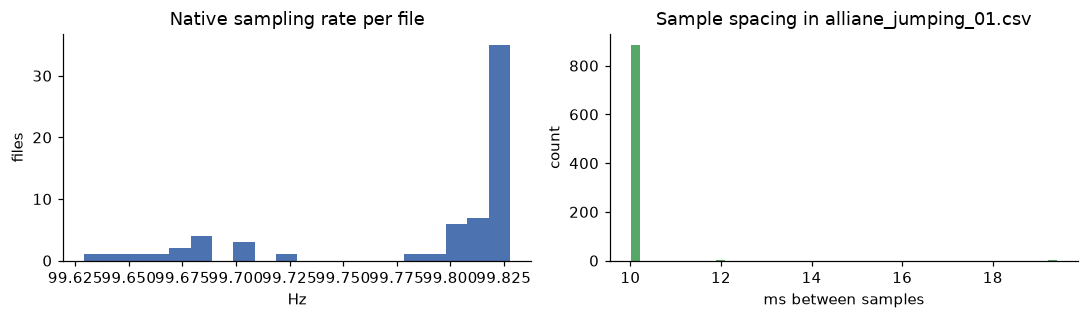

In [4]:
# Sampling rate report (goes in the report's data-collection section)
fs = info["native_fs"]
print(f"Native sampling rate: median {fs.median():.1f} Hz, min {fs.min():.1f} Hz, max {fs.max():.1f} Hz")
print(f"Timestamp jitter: median {info.jitter_pct.median():.1f} % of the sampling interval")

r0 = train_recs[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(fs, bins=20, color="#4C72B0")
ax[0].set(title="Native sampling rate per file", xlabel="Hz", ylabel="files")
ax[1].hist(1000 * np.diff(r0["df"]["timestamp"]), bins=50, color="#55A868")
ax[1].set(title=f"Sample spacing in {r0['file']}", xlabel="ms between samples", ylabel="count")
plt.tight_layout(); savefig("sampling_rate"); plt.show()

## 2. Pre-processing: harmonising the sampling rate

The phone doesn't sample at a perfectly constant rate. The time between samples jitters a little (right-hand plot above), and a different phone or app setting could record at a different rate altogether. So I put every recording on the same uniform 50 Hz grid.

First I interpolate each recording onto an evenly spaced grid at its own native rate, because the filter in the next step assumes even spacing. If the native rate is above 50 Hz, I then apply a 4th-order zero-phase Butterworth low-pass filter at 20 Hz to avoid aliasing (the Nyquist limit at 50 Hz is 25 Hz). Finally I interpolate onto the 50 Hz grid and cut 0.5 s from each end of the clip, since those samples include my tap on the screen to start or stop the recording.

I chose 50 Hz because almost all the energy of human movement is below 20 Hz, and walking and jumping are around 1 to 3 Hz. It is also below the phone's native rate, so I never have to up-sample much, and it is the rate used in common activity recognition datasets such as UCI-HAR.

In [5]:
def resample(df, fs_target=TARGET_FS, trim_s=TRIM_S, cutoff_hz=20.0):
    t = df["timestamp"].to_numpy(float)
    t = t - t[0]
    X = df[SIGNALS].to_numpy(float)
    fs_native = (len(t) - 1) / t[-1]

    # 1) uniform grid at the native rate
    t_u = np.arange(0, t[-1], 1 / fs_native)
    X_u = np.column_stack([np.interp(t_u, t, X[:, j]) for j in range(X.shape[1])])
    # 2) anti-alias filter when down-sampling
    if fs_native > fs_target * 1.05:
        b, a = butter(4, cutoff_hz / (fs_native / 2))
        X_u = filtfilt(b, a, X_u, axis=0)
    # 3) target grid, trimmed at both ends
    t_new = np.arange(trim_s, t[-1] - trim_s, 1 / fs_target)
    X_new = np.column_stack([np.interp(t_new, t_u, X_u[:, j]) for j in range(X.shape[1])])
    labels = df["activity"].to_numpy()[np.clip(np.searchsorted(t, t_new), 0, len(t) - 1)]

    out = pd.DataFrame(X_new, columns=SIGNALS)
    out.insert(0, "t", t_new)
    out["activity"] = labels
    return out

for r in train_recs + test_recs:
    r["rs"] = resample(r["df"])
print("Resampled", len(train_recs) + len(test_recs), "recordings to", TARGET_FS, "Hz")

Resampled 64 recordings to 50 Hz


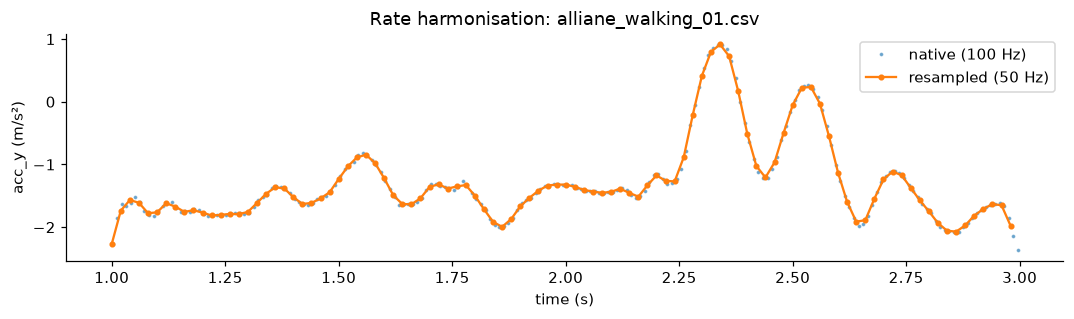

In [6]:
# Native vs resampled signal (zoom on 2 s of a walking clip)
r = next((r for r in train_recs if r["activity"] == "walking"), train_recs[0])
t_nat = r["df"]["timestamp"] - r["df"]["timestamp"].iloc[0]
m = (t_nat > 1) & (t_nat < 3)
m2 = (r["rs"]["t"] > 1) & (r["rs"]["t"] < 3)
plt.figure(figsize=(10, 3))
plt.plot(t_nat[m], r["df"]["acc_y"][m], ".", ms=3, alpha=.5, label=f"native ({r['native_fs']:.0f} Hz)")
plt.plot(r["rs"]["t"][m2], r["rs"]["acc_y"][m2], "-o", ms=3, label=f"resampled ({TARGET_FS} Hz)")
plt.title(f"Rate harmonisation: {r['file']}"); plt.xlabel("time (s)"); plt.ylabel("acc_y (m/s²)")
plt.legend(); plt.tight_layout(); savefig("resampling"); plt.show()

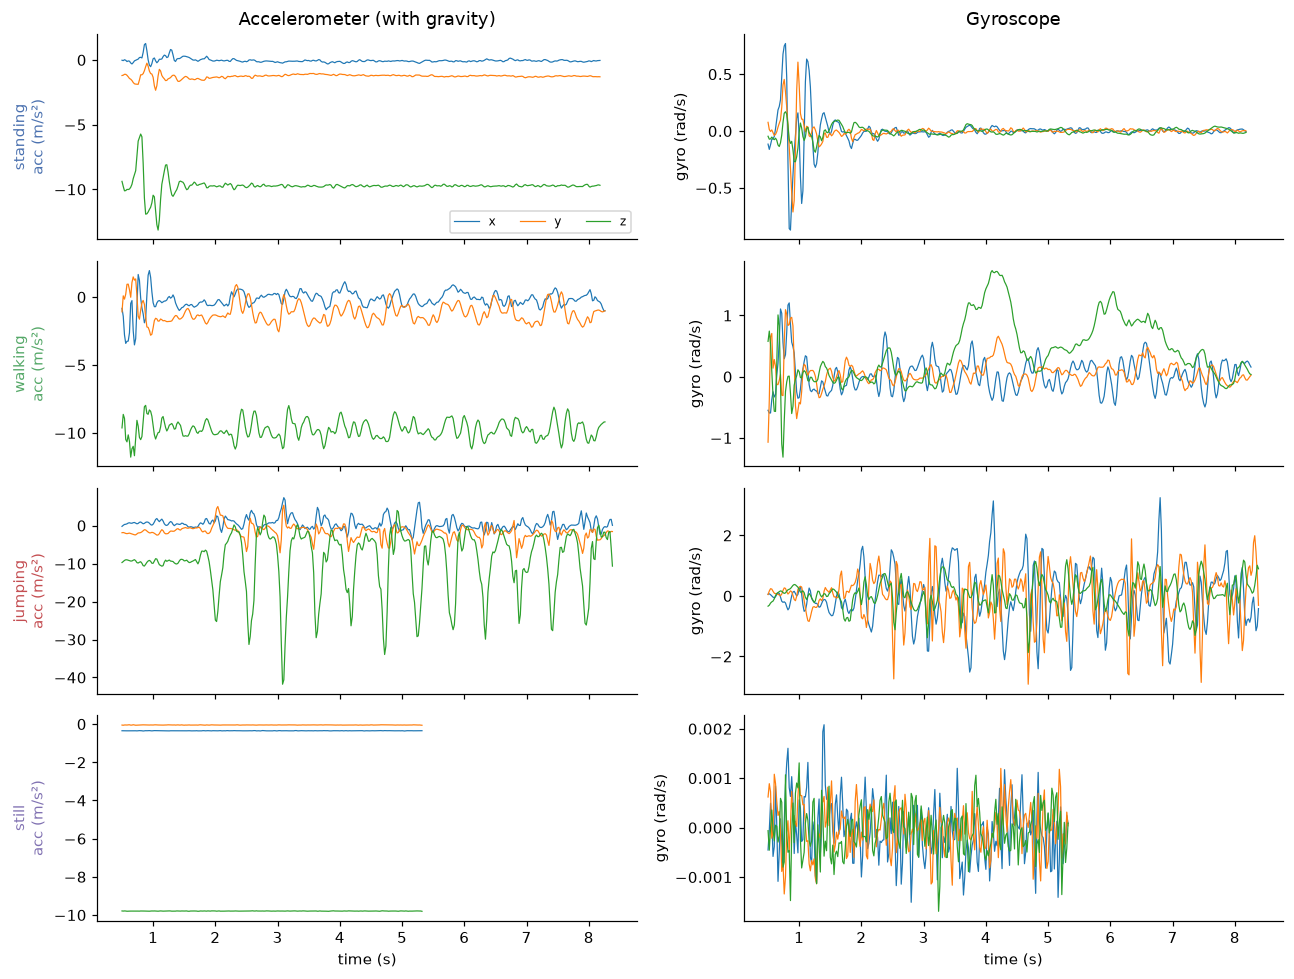

In [7]:
# One example recording per activity
fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(12, 9), sharex=True)
for i, act in enumerate(ACTIVITIES):
    r = next((r for r in train_recs if r["activity"] == act), None)
    if r is None:
        continue
    rs = r["rs"]
    for j, ax_name in enumerate("xyz"):
        axes[i, 0].plot(rs["t"], rs[f"acc_{ax_name}"], lw=.8, label=ax_name)
        axes[i, 1].plot(rs["t"], rs[f"gyro_{ax_name}"], lw=.8, label=ax_name)
    axes[i, 0].set_ylabel(f"{act}\nacc (m/s²)", color=COLORS[act])
    axes[i, 1].set_ylabel("gyro (rad/s)")
axes[0, 0].set_title("Accelerometer (with gravity)"); axes[0, 1].set_title("Gyroscope")
axes[0, 0].legend(ncol=3, fontsize=8); axes[-1, 0].set_xlabel("time (s)"); axes[-1, 1].set_xlabel("time (s)")
plt.tight_layout(); savefig("raw_signals"); plt.show()

## 3. Windowing

I split each resampled signal into 2 s windows (100 samples at 50 Hz) and start a new window every 1 s, so neighbouring windows overlap by 50%.

The window length follows from the sampling rate and how fast the movements are. Walking cadence is usually about 1.6 to 2.2 steps per second and jumping about 1.5 to 2.5 jumps per second, so a 2 s window holds at least three full cycles and the statistics are stable. At 50 Hz, 100 samples give an FFT frequency spacing of 50 / 100 = 0.5 Hz, which is fine enough to tell a 1.5 Hz rhythm from a 2.5 Hz one. A longer window would leave too few windows in a 7 s clip (I get about 5 after trimming).

The overlap doubles the number of observations, and it means a change of activity is never more than 1 s from a window boundary. Each window gets the label that covers most of its samples.

In [8]:
WIN = int(WINDOW_S * TARGET_FS)
HOP = int(HOP_S * TARGET_FS)

def iter_windows(rs):
    X, y = rs[SIGNALS].to_numpy(), rs["activity"].to_numpy()
    for s in range(0, len(rs) - WIN + 1, HOP):
        labs, counts = np.unique(y[s:s + WIN], return_counts=True)
        yield X[s:s + WIN], labs[counts.argmax()], rs["t"].iloc[s]

## 4. Feature extraction

Most features use the magnitude of the acceleration, |a| = √(x² + y² + z²), because it stays the same when the phone rotates in my hand. I also kept the mean of each axis, because those show which way gravity points and so how the phone is tilted.

| Feature | Domain | Why I use it |
|---|---|---|
| `acc_x_mean`, `acc_y_mean`, `acc_z_mean` | time | Direction of gravity, which shows how the phone is tilted. I held the phone flat and screen up at my waist, and it also lay flat on the table for still, so gravity is mostly on z in every activity. Jumping tilts the phone a little more towards y. |
| `log_acc_mag_std` | time | How much I'm moving: still is only sensor noise, standing has the small shake of my hand, walking is moderate and jumping is large. Because the phone lies the same way when standing and still, this small difference is what separates those two. |
| `log_acc_mag_range` | time | Peak-to-peak size of the signal. Landing from a jump gives spikes of 2 to 4 g, much more than walking. |
| `log_acc_sma` | time | Signal magnitude area of the acceleration with gravity removed, a standard measure of activity level in HAR. |
| `log_gyro_mag_mean`, `log_gyro_mag_std` | time | Rotation. My hips swing the phone when I walk, and a phone on a table doesn't rotate at all. |
| `acc_corr_xy`, `acc_corr_xz`, `acc_corr_yz` | time | How the axes move together. Jumping is mostly along one vertical axis, while walking mixes vertical and forward motion. In noise-only windows the correlation is close to 0. |
| `acc_dom_freq` | frequency (FFT) | The step or jump rate. Still and standing have no clear peak. |
| `log_acc_dom_power` | frequency (FFT) | How strong that rhythm is. |
| `acc_band_ratio` | frequency (FFT) | Share of the spectral energy between 0.5 and 5 Hz, where human movement sits. Rhythmic movement puts its energy there, while sensor noise spreads it over all frequencies. |
| `acc_spec_entropy` | frequency (FFT) | How flat the spectrum is: low for rhythmic movement, high for white noise such as the still state. |
| `gyro_dom_freq` | frequency (FFT) | The rotation rhythm, since the hips rotate once per stride. |

The intensity features range over several orders of magnitude (around 0.01 m/s² for still and over 10 m/s² for jumping), so I take their log first. That brings each activity's values closer to the Gaussian shape the emission model assumes.

For the FFT I remove the mean, apply a Hann window and zero-pad to 256 points. The padding only samples the spectrum on a finer grid and doesn't add real resolution. I ignore the zero-frequency bin.

In [9]:
EPS = 1e-6

def _corr(a, b):
    if a.std() < 1e-8 or b.std() < 1e-8:
        return 0.0
    return float(np.corrcoef(a, b)[0, 1])

def _spectrum(sig, fs=TARGET_FS, n_fft=256):
    sig = (sig - sig.mean()) * np.hanning(len(sig))
    power = np.abs(np.fft.rfft(sig, n=n_fft)) ** 2
    freqs = np.fft.rfftfreq(n_fft, 1 / fs)
    return freqs[1:], power[1:]            # drop DC

def extract_features(w, fs=TARGET_FS):
    acc, gyr = w[:, :3], w[:, 3:]
    amag, gmag = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    f = {}
    # time domain
    f["acc_x_mean"], f["acc_y_mean"], f["acc_z_mean"] = acc.mean(axis=0)
    f["log_acc_mag_std"] = np.log(amag.std() + EPS)
    f["log_acc_mag_range"] = np.log(np.ptp(amag) + EPS)
    f["log_acc_sma"] = np.log(np.abs(acc - acc.mean(axis=0)).sum(axis=1).mean() + EPS)
    f["log_gyro_mag_mean"] = np.log(gmag.mean() + EPS)
    f["log_gyro_mag_std"] = np.log(gmag.std() + EPS)
    for (i, j), name in zip([(0, 1), (0, 2), (1, 2)], ["xy", "xz", "yz"]):
        f[f"acc_corr_{name}"] = _corr(acc[:, i], acc[:, j])
    # frequency domain (FFT)
    freqs, p = _spectrum(amag, fs)
    k = p.argmax()
    f["acc_dom_freq"] = freqs[k]
    f["log_acc_dom_power"] = np.log(p[k] + EPS)
    band = (freqs >= 0.5) & (freqs <= 5.0)
    f["acc_band_ratio"] = p[band].sum() / (p.sum() + EPS)
    q = p / (p.sum() + EPS)
    f["acc_spec_entropy"] = -(q * np.log(q + EPS)).sum() / np.log(len(q))
    gfreqs, gp = _spectrum(gmag, fs)
    f["gyro_dom_freq"] = gfreqs[gp.argmax()]
    return f

def featurise(recs):
    rows = []
    for r in recs:
        for k, (w, lab, t0) in enumerate(iter_windows(r["rs"])):
            rows.append({"file": r["file"], "start": r["start"], "t": t0, "win": k,
                         "activity": lab, **extract_features(w)})
    return pd.DataFrame(rows)

train_feat = featurise(train_recs)
test_feat = featurise(test_recs) if test_recs else pd.DataFrame()
FEATURES = [c for c in train_feat.columns if c not in ("file", "start", "t", "win", "activity")]
print(f"{len(FEATURES)} features, {len(train_feat)} training windows, {len(test_feat)} test windows")
display(train_feat.groupby("activity")[FEATURES].mean().reindex(ACTIVITIES).T.round(2))

16 features, 267 training windows, 129 test windows


activity,standing,walking,jumping,still
acc_x_mean,-0.13,-0.12,0.82,-0.46
acc_y_mean,-1.02,-1.40,-2.17,-0.29
acc_z_mean,-9.75,-9.71,-9.42,-9.78
log_acc_mag_std,-2.77,-0.32,2.09,-5.46
log_acc_mag_range,-1.11,1.27,3.56,-3.85
log_acc_sma,-2.08,0.33,2.24,-4.58
log_gyro_mag_mean,-3.71,-1.02,0.38,-6.95
log_gyro_mag_std,-4.32,-1.61,-0.14,-7.67
acc_corr_xy,0.04,0.07,-0.22,-0.06
acc_corr_xz,0.04,-0.08,-0.23,-0.02


### Normalisation

I z-score every feature: subtract the training mean and divide by the training standard deviation. The raw features are in completely different units (Hz, m/s², and unitless correlations and ratios), and the emission model uses the same variance floor for every feature, which only makes sense once they share a scale. I preferred z-scoring to min-max scaling because a single hard jump landing would set the maximum and squash all the other values into a narrow range.

The mean and standard deviation come from the training windows only and are applied unchanged to the test windows, so nothing from the test set leaks into training.

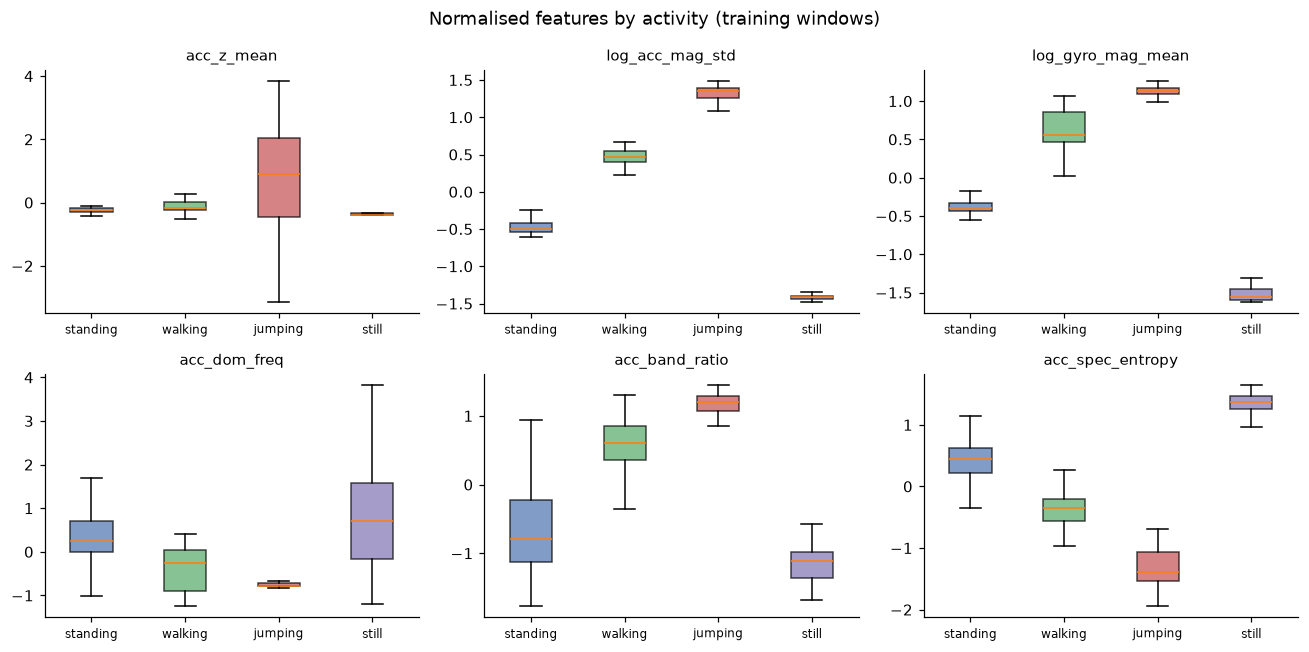

In [10]:
feat_mu = train_feat[FEATURES].mean()
feat_sd = train_feat[FEATURES].std().replace(0, 1.0)

def normalise(df):
    out = df.copy()
    out[FEATURES] = (df[FEATURES] - feat_mu) / feat_sd
    return out

train_n = normalise(train_feat)
test_n = normalise(test_feat) if len(test_feat) else test_feat

show = ["acc_z_mean", "log_acc_mag_std", "log_gyro_mag_mean", "acc_dom_freq", "acc_band_ratio", "acc_spec_entropy"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, feat in zip(axes.ravel(), show):
    data = [train_n.loc[train_n.activity == a, feat] for a in ACTIVITIES]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    ax.set_xticks(range(1, len(ACTIVITIES) + 1), ACTIVITIES)
    for patch, a in zip(bp["boxes"], ACTIVITIES):
        patch.set_facecolor(COLORS[a]); patch.set_alpha(.7)
    ax.set_title(feat, fontsize=10); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Normalised features by activity (training windows)")
plt.tight_layout(); savefig("feature_distributions"); plt.show()

## 5. HMM components

| Element | In my model |
|---|---|
| Hidden states Z | The 4 activities: standing, walking, jumping, still (K = 4) |
| Observations X | One z-scored 16-dimensional feature vector per 2 s window |
| Transitions A | A_ij = P(z_t = j \| z_{t-1} = i), the probability of going from activity i to activity j in one 1 s step |
| Emissions B | p(x \| z = k) = N(x; μ_k, diag(σ²_k)), a Gaussian with diagonal covariance |
| Initial probabilities π | π_k = P(z_1 = k) |

I used a diagonal covariance because I only have about 60 to 80 training windows per activity. A full 16 × 16 covariance needs 136 numbers per state, which I can't estimate reliably from that much data, while a diagonal one needs 16. I also set a variance floor of 0.01 (in z-units) so no variance can collapse to zero, which could otherwise happen with the near-zero gyroscope readings of the still state.

### Which algorithms and why

Viterbi is my decoder. It finds the single most likely sequence of activities, argmax P(Z | X), which gives one label per window, and that is what accuracy, sensitivity and specificity are computed on. It also uses the transition matrix, so an isolated window that looks like jumping in the middle of a walk gets corrected, because staying in the same state is much more likely. This is where I expect the HMM to beat a classifier that looks at each window on its own.

The forward algorithm gives the likelihood P(X | θ) of a recording, which I use to monitor training, and forward-backward gives the state posteriors that Baum-Welch needs.

Since my training clips are labelled, I first estimate π, A and B by counting. Baum-Welch (EM using forward-backward) then refines them on the full training sequences and stops once the mean log-likelihood per window improves by less than ε = 10⁻⁴. In both stages I add one to every count in π and A, so a transition that never appears in my training data keeps a small probability instead of exactly zero. Baum-Welch maximises likelihood rather than accuracy, so in section 7 I compare the test results of the counting-only model with the refined one.

Everything runs in log space with log-sum-exp, because multiplying a few hundred probabilities together would round to zero.

In [11]:
def logsumexp(a, axis=None, keepdims=False):
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis=axis)


class GaussianHMM:
    # Hidden Markov Model with diagonal-covariance Gaussian emissions (numpy, log space).
    #
    # Parameters: pi (K,), A (K, K), means (K, D), vars (K, D).

    def __init__(self, states, min_var=1e-2, pseudocount=1.0):
        self.states = list(states)
        self.K = len(self.states)
        self.min_var = min_var
        self.pseudocount = pseudocount

    # ---------- parameter initialisation ----------
    def init_supervised(self, seqs, labels):
        # Maximum-likelihood estimates from labelled sequences, with add-one smoothing on pi and A.
        pseudocount = self.pseudocount
        idx = {s: i for i, s in enumerate(self.states)}
        X = np.vstack(seqs)
        z = np.concatenate([[idx[l] for l in lab] for lab in labels])
        missing = [s for k, s in enumerate(self.states) if not (z == k).any()]
        assert not missing, f"no training windows for {missing}"
        self.means = np.array([X[z == k].mean(axis=0) for k in range(self.K)])
        self.vars = np.maximum(np.array([X[z == k].var(axis=0) for k in range(self.K)]), self.min_var)
        A = np.full((self.K, self.K), pseudocount)
        pi = np.full(self.K, pseudocount)
        for lab in labels:
            zz = [idx[l] for l in lab]
            pi[zz[0]] += 1
            for a, b in zip(zz[:-1], zz[1:]):
                A[a, b] += 1
        self.A = A / A.sum(axis=1, keepdims=True)
        self.pi = pi / pi.sum()
        return self

    def copy(self):
        new = GaussianHMM(self.states, self.min_var, self.pseudocount)
        for p in ("pi", "A", "means", "vars"):
            setattr(new, p, getattr(self, p).copy())
        return new

    # ---------- emissions ----------
    def log_emission(self, X):
        # log N(x_t | mu_k, diag(var_k)) for every window t and state k -> (T, K)
        diff = X[:, None, :] - self.means[None]
        return -0.5 * np.sum(diff ** 2 / self.vars[None] + np.log(2 * np.pi * self.vars[None]), axis=2)

    # ---------- forward / backward ----------
    def forward(self, logB):
        T, logA = len(logB), np.log(self.A)
        la = np.empty((T, self.K))
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logsumexp(la[t - 1][:, None] + logA, axis=0) + logB[t]
        return la, logsumexp(la[-1])

    def backward(self, logB):
        T, logA = len(logB), np.log(self.A)
        lb = np.zeros((T, self.K))
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        return lb

    def score(self, X):
        # log P(X | model) via the forward algorithm.
        return self.forward(self.log_emission(X))[1]

    def _e_step(self, X):
        logB = self.log_emission(X)
        la, ll = self.forward(logB)
        lb = self.backward(logB)
        gamma = np.exp(la + lb - ll)                                     # P(z_t = k | X)
        if len(X) > 1:
            log_xi = (la[:-1, :, None] + np.log(self.A)[None]
                      + (logB[1:] + lb[1:])[:, None, :] - ll)           # P(z_t = i, z_t+1 = j | X)
            xi = np.exp(logsumexp(log_xi, axis=0))
        else:
            xi = np.zeros((self.K, self.K))
        return gamma, xi, ll

    def posteriors(self, X):
        return self._e_step(X)[0]

    # ---------- Baum-Welch ----------
    def fit(self, seqs, tol=1e-4, max_iter=200, verbose=True):
        # Baum-Welch (EM). Stops when the mean per-window log-likelihood improves by less than tol.
        # max_iter is only a safety cap; self.converged records which criterion stopped training.
        n_obs = sum(len(X) for X in seqs)
        self.history, self.converged = [], False
        for it in range(max_iter):
            g0 = np.zeros(self.K); xi_sum = np.zeros((self.K, self.K))
            w = np.zeros(self.K); wx = np.zeros_like(self.means); wxx = np.zeros_like(self.means)
            ll_total = 0.0
            for X in seqs:
                gamma, xi, ll = self._e_step(X)
                g0 += gamma[0]; xi_sum += xi
                w += gamma.sum(axis=0); wx += gamma.T @ X; wxx += gamma.T @ X ** 2
                ll_total += ll
            self.history.append(ll_total / n_obs)
            if verbose:
                print(f"iter {it:3d}  mean log-lik per window = {self.history[-1]:.5f}")
            if it > 0:
                delta = self.history[-1] - self.history[-2]
                if delta < -tol:
                    print(f"  warning: log-likelihood decreased by {-delta:.2e}")
                if abs(delta) < tol:
                    self.converged = True
                    break
            # M-step
            # add-one (Dirichlet) smoothing, as in init_supervised: a transition never seen in training
            # (e.g. leaving the last activity recorded) keeps a small non-zero probability
            self.pi = (g0 + self.pseudocount) / (g0.sum() + self.K * self.pseudocount)
            A = xi_sum + self.pseudocount
            self.A = A / A.sum(axis=1, keepdims=True)
            self.means = wx / w[:, None]
            self.vars = np.maximum(wxx / w[:, None] - self.means ** 2, self.min_var)
        if verbose:
            print("converged" if self.converged else f"stopped at max_iter={max_iter} without converging",
                  f"after {len(self.history)} iterations")
        return self

    # ---------- decoding ----------
    def viterbi(self, X):
        # Most probable state path. Returns (state indices, log P(path, X)).
        logB, logA = self.log_emission(X), np.log(self.A)
        T = len(X)
        delta = np.empty((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA                      # (from, to)
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

    def predict(self, X):
        return np.array(self.states)[self.viterbi(X)[0]]

    def predict_emission_only(self, X):
        # Baseline: ignore transitions, pick the most likely state for each window independently.
        return np.array(self.states)[(self.log_emission(X) + np.log(self.pi)).argmax(axis=1)]

In [12]:
# Sanity check on synthetic data: sample from a known HMM, check Viterbi recovers most of the path
rng = np.random.default_rng(0)
true = GaussianHMM(["a", "b", "c"])
true.pi = np.array([.6, .3, .1])
true.A = np.array([[.9, .08, .02], [.05, .9, .05], [.02, .08, .9]])
true.means = np.array([[-2., 0.], [0., 2.], [2., -1.]]); true.vars = np.full((3, 2), .5)
z = [rng.choice(3, p=true.pi)]
for _ in range(499):
    z.append(rng.choice(3, p=true.A[z[-1]]))
z = np.array(z)
Xs = true.means[z] + rng.normal(0, np.sqrt(.5), (500, 2))
print("Viterbi accuracy on synthetic sequence:", (true.viterbi(Xs)[0] == z).mean().round(3))
assert np.isclose(np.exp(logsumexp(true.forward(true.log_emission(Xs))[0][-1] - true.score(Xs))), 1.0)

Viterbi accuracy on synthetic sequence: 0.994


## 6. Training

A single training clip is just a short run of windows with the same label, so on its own it says nothing about how one activity follows another. To give the model transitions to learn from, I sort the clips by the time I recorded them and join clips recorded less than 5 minutes apart into one session sequence.

Training has two stages. First I estimate π, A, μ and σ² directly from the labels, then Baum-Welch refines all of them until the log-likelihood stops improving.

In [13]:
def build_sequences(norm_df, session_gap_s=None):
    # Group windows into sequences. session_gap_s=None -> one sequence per file.
    files = (norm_df.groupby("file")["start"].first().sort_values())
    groups, current, last_end = [], [], None
    for f, start in files.items():
        dur = norm_df.loc[norm_df.file == f, "t"].max() + WINDOW_S
        if session_gap_s is None or (last_end is not None and start - last_end > session_gap_s):
            if current:
                groups.append(current)
            current = []
        current.append(f)
        last_end = start + dur
    if current:
        groups.append(current)
    seqs, labels, names = [], [], []
    for g in groups:
        part = pd.concat([norm_df[norm_df.file == f].sort_values("win") for f in g])
        seqs.append(part[FEATURES].to_numpy()); labels.append(part["activity"].to_numpy()); names.append(g)
    return seqs, labels, names

train_seqs, train_labels, train_groups = build_sequences(train_n, SESSION_GAP_S)
print(f"{len(train_seqs)} training session(s); lengths (windows):", [len(s) for s in train_seqs])

hmm_sup = GaussianHMM(ACTIVITIES).init_supervised(train_seqs, train_labels)
hmm = hmm_sup.copy().fit(train_seqs, tol=1e-4, max_iter=200)

def accuracy(model, seqs, labels):
    pred = np.concatenate([model.predict(X) for X in seqs])
    return (pred == np.concatenate(labels)).mean()

print(f"\nTraining accuracy - supervised init: {accuracy(hmm_sup, train_seqs, train_labels):.3f}"
      f" | after Baum-Welch: {accuracy(hmm, train_seqs, train_labels):.3f}")

3 training session(s); lengths (windows): [144, 36, 87]


iter   0  mean log-lik per window = -2.07628
iter   1  mean log-lik per window = -1.74508
iter   2  mean log-lik per window = -1.68260
iter   3  mean log-lik per window = -1.68260
converged after 4 iterations

Training accuracy - supervised init: 0.989 | after Baum-Welch: 0.985


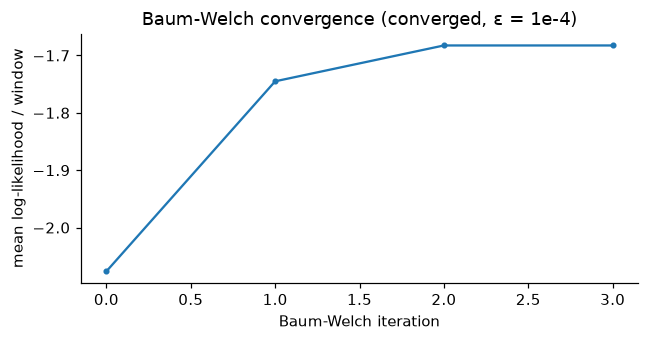

In [14]:
plt.figure(figsize=(6, 3.2))
plt.plot(hmm.history, "o-", ms=3)
plt.xlabel("Baum-Welch iteration"); plt.ylabel("mean log-likelihood / window")
plt.title(f"Baum-Welch convergence ({'converged' if hmm.converged else 'not converged'}, ε = 1e-4)")
plt.tight_layout(); savefig("baum_welch_convergence"); plt.show()

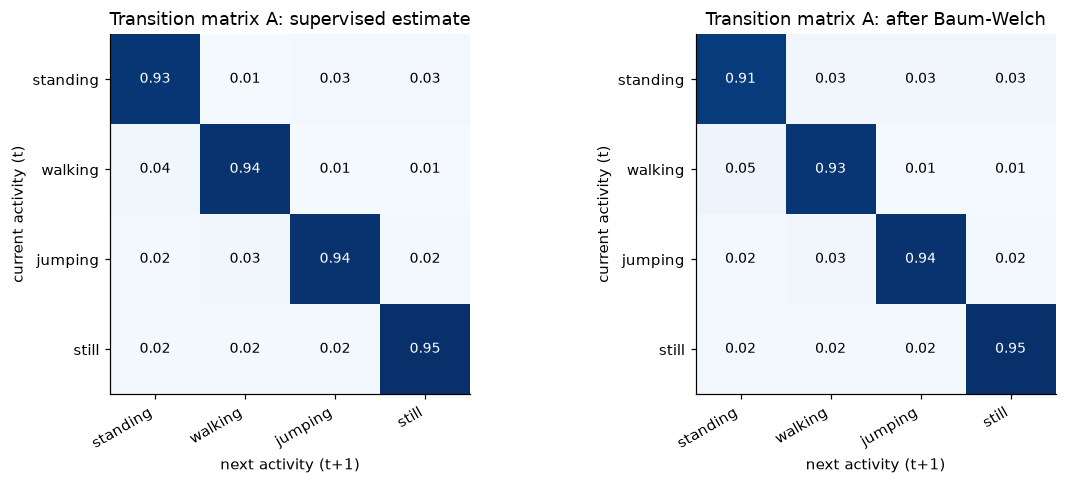

π (initial probabilities): {'standing': 0.143, 'walking': 0.286, 'jumping': 0.286, 'still': 0.286}
Expected time spent in each activity before switching, HOP / (1 - A_kk):
  standing    11.0 s
  walking     14.2 s
  jumping     16.2 s
  still       21.3 s


In [15]:
def plot_matrix(ax, M, labels, title, fmt="{:.2f}", cmap="Blues", xlabels=None):
    im = ax.imshow(M, cmap=cmap, vmin=0, vmax=M.max() if M.max() > 0 else 1)
    ax.set_xticks(range(M.shape[1]), xlabels or labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > 0.6 * M.max() else "black", fontsize=9)
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_matrix(axes[0], hmm_sup.A, ACTIVITIES, "Transition matrix A: supervised estimate")
plot_matrix(axes[1], hmm.A, ACTIVITIES, "Transition matrix A: after Baum-Welch")
for ax in axes:
    ax.set_xlabel("next activity (t+1)"); ax.set_ylabel("current activity (t)")
plt.tight_layout(); savefig("transition_matrix"); plt.show()

print("π (initial probabilities):", {a: round(float(p), 3) for a, p in zip(ACTIVITIES, hmm.pi)})
print("Expected time spent in each activity before switching, HOP / (1 - A_kk):")
for k, a in enumerate(ACTIVITIES):
    print(f"  {a:9s} {HOP_S / (1 - hmm.A[k, k]):6.1f} s")

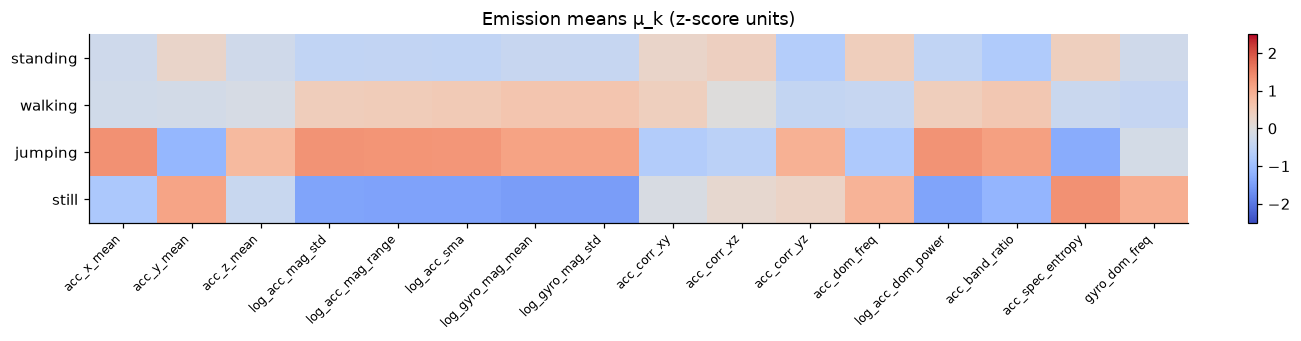

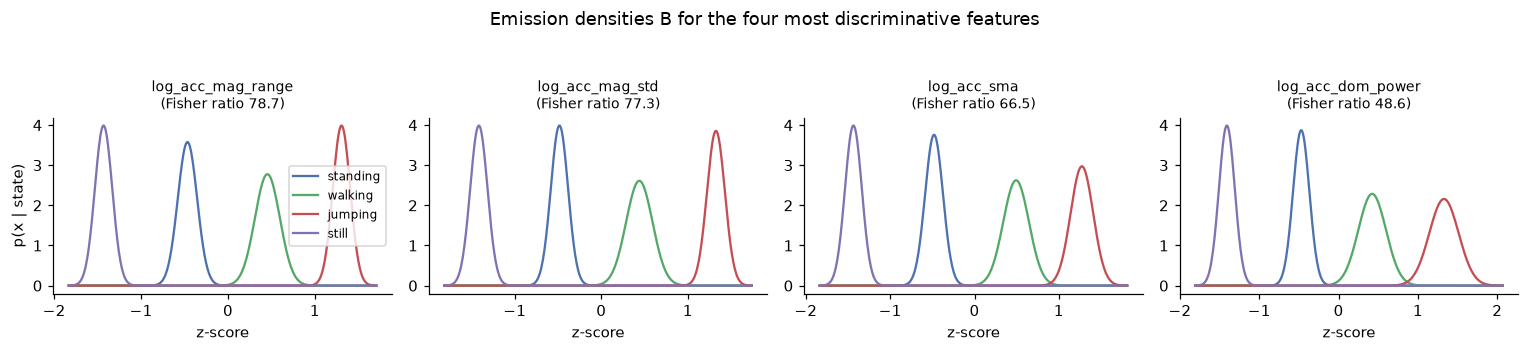

In [16]:
# Emission probabilities: per-state Gaussian means (heatmap) and densities for the most separating features
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(hmm.means, cmap="coolwarm", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(ACTIVITIES)), ACTIVITIES)
ax.set_title("Emission means μ_k (z-score units)")
plt.colorbar(im, ax=ax, fraction=.02)
plt.tight_layout(); savefig("emission_means"); plt.show()

# Fisher ratio = between-state variance of the means / mean within-state variance
fisher = hmm.means.var(axis=0) / hmm.vars.mean(axis=0)
top = np.argsort(fisher)[::-1][:4]
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, d in zip(axes, top):
    sds = np.sqrt(hmm.vars[:, d])
    xs = np.linspace((hmm.means[:, d] - 4 * sds).min(), (hmm.means[:, d] + 4 * sds).max(), 400)
    for k, a in enumerate(ACTIVITIES):
        sd = np.sqrt(hmm.vars[k, d])
        ax.plot(xs, np.exp(-0.5 * ((xs - hmm.means[k, d]) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)),
                color=COLORS[a], label=a)
    ax.set_title(f"{FEATURES[d]}\n(Fisher ratio {fisher[d]:.1f})", fontsize=9); ax.set_xlabel("z-score")
axes[0].set_ylabel("p(x | state)"); axes[0].legend(fontsize=8)
plt.suptitle("Emission densities B for the four most discriminative features", y=1.05)
plt.tight_layout(); savefig("emission_densities"); plt.show()

## 7. Evaluation on unseen data

I decode each test recording separately with Viterbi. None of these windows were used for the normalisation statistics or for training the HMM.

Each test recording is one continuous session with all four activities. The few seconds between activities (for example while I put the phone down on the table) are labelled `transition`. Viterbi still decodes them as part of the sequence, but they are left out of the metrics because they don't belong to any of the four classes.

For each activity k, treated as one class against the rest:

| Metric | Formula | What it tells me |
|---|---|---|
| Sensitivity | TP / (TP + FN) | Of the windows that really are k, how many the model labelled k |
| Specificity | TN / (TN + FP) | Of the windows that are not k, how many the model correctly left unlabelled as k |
| Overall accuracy | correct windows / all windows | Accuracy across all four activities |

In [17]:
assert len(test_n), "No test files in data/test - record unseen data first."

test_seqs, test_labels, test_groups = build_sequences(test_n, session_gap_s=None)  # one sequence per file

def confusion(y_true, y_pred, labels=ACTIVITIES):
    cm = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[labels.index(t), labels.index(p)] += 1
    return cm

def metrics_table(cm, labels=ACTIVITIES):
    total, acc = cm.sum(), np.trace(cm) / cm.sum()
    rows = []
    for k, a in enumerate(labels):
        tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = total - tp - fn - fp
        rows.append({"State (Activity)": a, "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan,
                     "Overall Accuracy": acc})
    return pd.DataFrame(rows).set_index("State (Activity)")

y_true = np.concatenate(test_labels)
scored = y_true != "transition"          # windows that belong to one of the four activities
preds = {
    "HMM (Baum-Welch): Viterbi": np.concatenate([hmm.predict(X) for X in test_seqs]),
    "HMM (supervised only): Viterbi": np.concatenate([hmm_sup.predict(X) for X in test_seqs]),
    "Emission only (no transitions)": np.concatenate([hmm.predict_emission_only(X) for X in test_seqs]),
}
y_pred = preds["HMM (Baum-Welch): Viterbi"]
print(f"{scored.sum()} scored test windows ({(~scored).sum()} transition windows left out)")
cm = confusion(y_true[scored], y_pred[scored])
results = metrics_table(cm)
display(results.round(3))

print("Comparison on the test set:")
for name, p in preds.items():
    print(f"  {name:34s} accuracy = {(p[scored] == y_true[scored]).mean():.3f}")

121 scored test windows (8 transition windows left out)


,Number of Samples,Sensitivity,Specificity,Overall Accuracy
State (Activity),,,,
standing,29,0.759,1.000,0.926
walking,33,0.970,0.909,0.926
jumping,30,1.000,0.989,0.926
still,29,0.966,1.000,0.926


Comparison on the test set:
  HMM (Baum-Welch): Viterbi          accuracy = 0.926
  HMM (supervised only): Viterbi     accuracy = 0.942
  Emission only (no transitions)     accuracy = 0.926


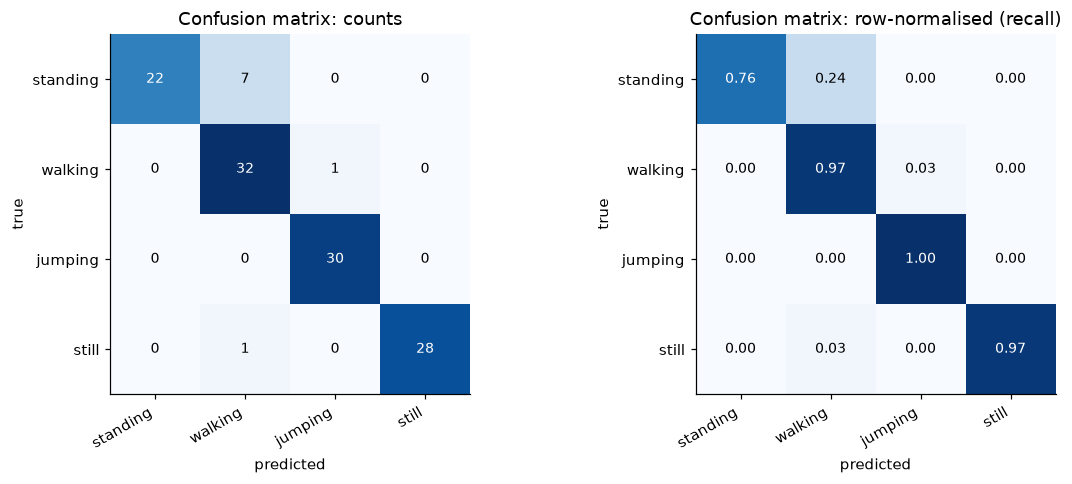

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_matrix(axes[0], cm.astype(float), ACTIVITIES, "Confusion matrix: counts", fmt="{:.0f}")
row_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
plot_matrix(axes[1], row_norm, ACTIVITIES, "Confusion matrix: row-normalised (recall)")
for ax in axes:
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); savefig("confusion_matrix"); plt.show()

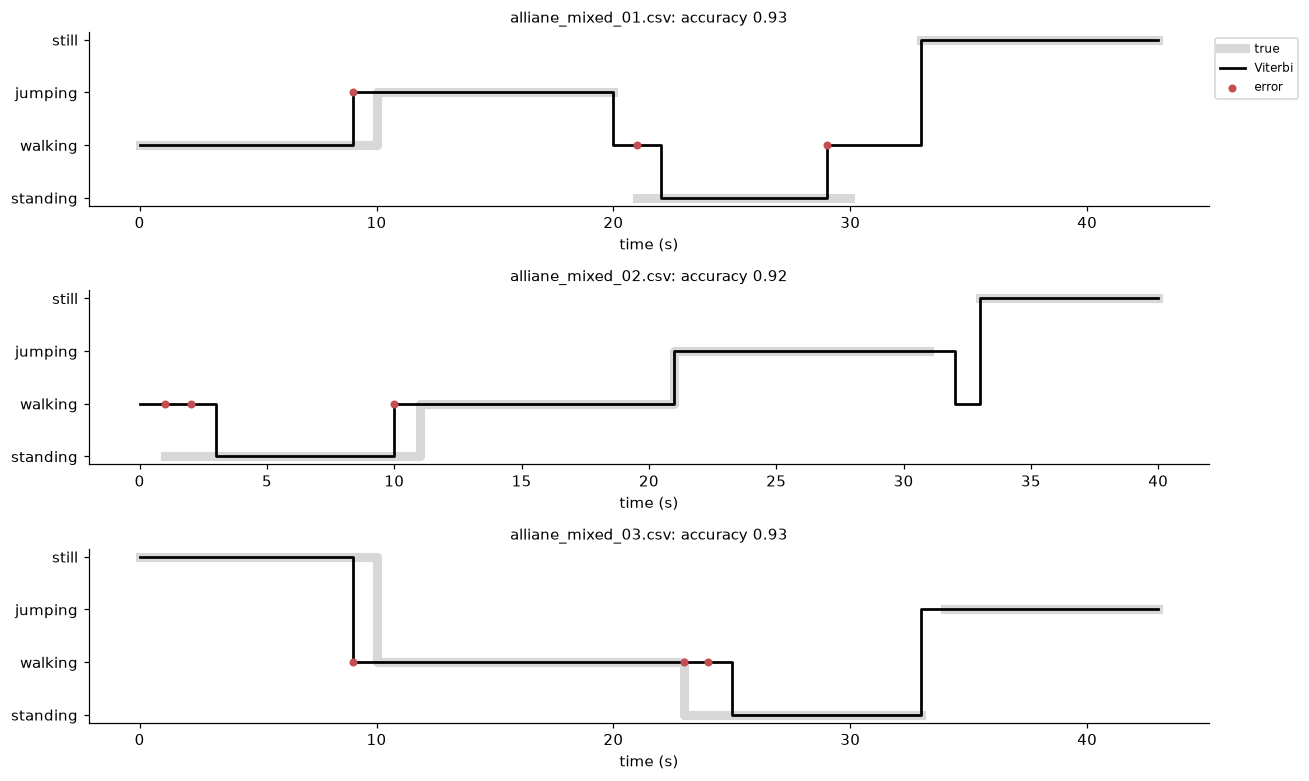

In [19]:
# Decoded sequences: true vs predicted activity over time for every test file
n = len(test_seqs)
fig, axes = plt.subplots(n, 1, figsize=(12, 2.4 * n), squeeze=False)
for ax, X, lab, files in zip(axes[:, 0], test_seqs, test_labels, test_groups):
    pred = hmm.predict(X)
    t = np.arange(len(X)) * HOP_S
    ti = np.array([ACTIVITIES.index(a) if a in ACTIVITIES else np.nan for a in lab])  # gap at transitions
    pi_ = np.array([ACTIVITIES.index(a) for a in pred])
    ax.step(t, ti, where="post", lw=6, alpha=.3, color="grey", label="true")
    ax.step(t, pi_, where="post", lw=1.8, color="black", label="Viterbi")
    keep = ~np.isnan(ti)
    wrong = keep & (ti != pi_)
    ax.scatter(t[wrong], pi_[wrong], color="#C44E52", zorder=3, s=18, label="error")
    ax.set_yticks(range(len(ACTIVITIES)), ACTIVITIES)
    ax.set_title(f"{', '.join(files)}: accuracy {1 - wrong.sum() / keep.sum():.2f}", fontsize=10)
    ax.set_xlabel("time (s)")
axes[0, 0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
plt.tight_layout(); savefig("decoded_sequences"); plt.show()

In [20]:
# Table in Markdown, ready to paste into the report
def to_markdown(df):
    cols = [df.index.name] + list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        cells = [str(idx)] + [str(int(v)) if c == "Number of Samples" else f"{v:.3f}"
                              for c, v in row.items()]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

print(to_markdown(results))

| State (Activity) | Number of Samples | Sensitivity | Specificity | Overall Accuracy |
|---|---|---|---|---|
| standing | 29 | 0.759 | 1.000 | 0.926 |
| walking | 33 | 0.970 | 0.909 | 0.926 |
| jumping | 30 | 1.000 | 0.989 | 0.926 |
| still | 29 | 0.966 | 1.000 | 0.926 |


## 8. Numbers for the analysis

This cell collects the numbers I use in the discussion section of the report: the most common confusions, the easiest and hardest activity, the accuracy on each test file, training versus test accuracy, and the sampling rates.

In [21]:
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], ACTIVITIES[i], ACTIVITIES[j]) for i in range(4) for j in range(4) if off[i, j]),
               reverse=True)
print("Most frequent confusions (true -> predicted):")
for c, a, b in pairs[:5]:
    print(f"  {a:9s} -> {b:9s} {c} windows")
if not pairs:
    print("  none")

sens = results["Sensitivity"]
print(f"\nEasiest activity (highest sensitivity): {sens.idxmax()} ({sens.max():.2f})")
print(f"Hardest activity (lowest sensitivity):  {sens.idxmin()} ({sens.min():.2f})")

print("\nPer test file accuracy:")
for X, lab, files in zip(test_seqs, test_labels, test_groups):
    k = lab != "transition"
    print(f"  {', '.join(files):40s} {(hmm.predict(X)[k] == lab[k]).mean():.3f}  ({k.sum()} scored windows)")

print(f"\nTraining vs test accuracy: {accuracy(hmm, train_seqs, train_labels):.3f} vs {(y_pred[scored] == y_true[scored]).mean():.3f}")
print(f"Native sampling rates used: {', '.join(f'{v:.0f}' for v in sorted(info.native_fs.round().unique()))} Hz"
      f" -> resampled to {TARGET_FS} Hz")

Most frequent confusions (true -> predicted):
  standing  -> walking   7 windows
  walking   -> jumping   1 windows
  still     -> walking   1 windows

Easiest activity (highest sensitivity): jumping (1.00)
Hardest activity (lowest sensitivity):  standing (0.76)

Per test file accuracy:
  alliane_mixed_01.csv                     0.925  (40 scored windows)
  alliane_mixed_02.csv                     0.921  (38 scored windows)
  alliane_mixed_03.csv                     0.930  (43 scored windows)

Training vs test accuracy: 0.985 vs 0.926
Native sampling rates used: 100 Hz -> resampled to 50 Hz


### Notes for the discussion

The confusion matrix and the sensitivities show which activities were hardest to separate. Standing was the hardest (sensitivity 0.76): all of its errors were windows labelled as walking at the start or end of a standing segment, while I was settling or about to move. Standing and still were never confused, even though I held the phone flat for both, because the small shake of my hand is still far above the noise of a phone lying on a table. Every error in the test sessions falls at a change of activity, where a 2 s window contains a bit of two activities.

The diagonal of the transition matrix (0.91 to 0.95) shows that each activity tends to last 11 to 21 s before switching. The off-diagonal values partly reflect the order in which I recorded the clips, so I read them with some caution.

For noise and sampling rate, the useful outputs are the sampling-rate histogram, the timestamp jitter, the noise level in the still windows and the effect of the anti-aliasing filter. Things that could improve the model are longer continuous recordings with natural transitions, more test sessions, other phone positions such as a pocket or bag, extra sensors like the barometer for jumps, and full-covariance or mixture emissions once there is more data.